# 01 - Mean-Variance Portfolio Optimization
*Codecademy: Analyze Financial Data with Python / Mean-Variance Portfolio Optimization*

Every investor wants high return **and** low risk - you can't max out both. Mean-variance optimization (Harry Markowitz, 1952) answers: *for the risk I'm willing to take, which mix of assets gives the highest expected return?*

| block | sections | question |
|---|---|---|
| Inputs | 1-5: Expected Return I-III, Covariance Matrix I-II | how much does each asset earn on average, and how do assets move together? |
| Efficient Frontier | 6-8 | which portfolios give the best return for each level of risk? |
| Diversification | 9-10: Diverse Portfolios Decrease Variance I-II | why mixing assets lowers risk |
| Review | 11 | |

**Key idea of the whole lesson:** two risky assets can make a *less* risky portfolio - as long as they don't move perfectly together.

Data: [`data/stock_data.csv`](../../data/stock_data.csv) - quarterly prices of six stocks, end of 2007 to Q1 2018. Every chart is saved to `charts/` and collected in this folder's [README](README.md).

In [1]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt

CHARTS = 'charts/'
path = '../../data/stock_data.csv'

## 1. Inputs: Expected Return I
**Task:** calculate the quarterly returns of the six stocks (`quarterly_returns`), then the average expected return of each one (`expected_returns_avg`).

**Why returns, not prices?** Prices can't be compared across stocks - Adobe at 230 and Jet Blue at 20 say nothing about which was the better investment. Percent returns put every asset on the same scale, and they are the y-axis of the efficient frontier.

In [2]:
stock_data = pd.read_csv(path)
print(stock_data.head())

returns_columns = list(stock_data.columns[1:])
quarterly_returns = stock_data[returns_columns].pct_change()

expected_returns_avg = quarterly_returns.mean()

print(expected_returns_avg)

         Date  Delta  Jet Blue  Chevron  Exxon  Adobe  Honeywell
0  2007-12-31  14.64      5.94    94.37  94.39  42.58      60.89
1  2008-03-31   8.65      5.45    84.95  85.69  35.69      55.72
2  2008-06-30   5.42      3.58    98.30  86.81  39.63      49.26
3  2008-09-30   7.50      4.70    78.85  75.62  36.72      41.55
4  2008-12-31  10.97      6.80    72.90  78.42  20.85      32.61
Delta        0.062093
Jet Blue     0.052361
Chevron      0.010323
Exxon       -0.002444
Adobe        0.053780
Honeywell    0.028439
dtype: float64


### How `pct_change()` works
Each row is compared with the row before it:

```text
return = (this quarter - last quarter) / last quarter

Delta:  14.64 -> 8.65    (8.65 - 14.64) / 14.64 = -0.409  ->  -40.9% in Q1 2008
first row: nothing before it -> NaN
```

- `.mean()` skips `NaN` automatically (R needs `colMeans(x, na.rm = TRUE)`).
- R equivalent of `pct_change()`: `x / dplyr::lag(x) - 1`.
- `columns[1:]` skips the `Date` column - it isn't a stock.

### Tip: keep the dates as the index
Above, the rows are numbered 0-41 - you can't see which quarter is which. Make `Date` the index when loading: the dates stay attached, and every column is a stock, so `columns[1:]` isn't needed:

In [3]:
stock_data = pd.read_csv(path, index_col='Date', parse_dates=True)   # Date column becomes the row labels, read as real dates
quarterly_returns = stock_data.pct_change()                            # every column is a stock now - no columns[1:] needed
print(quarterly_returns.head(3))                                       # first 3 rows

               Delta  Jet Blue   Chevron     Exxon     Adobe  Honeywell
Date                                                                   
2007-12-31       NaN       NaN       NaN       NaN       NaN        NaN
2008-03-31 -0.409153 -0.082492 -0.099820 -0.092171 -0.161813  -0.084907
2008-06-30 -0.373410 -0.343119  0.157151  0.013070  0.110395  -0.115937


- `index_col='Date'` - use this column as the row labels.
- `parse_dates=True` - read them as real dates, not text (needed for time-series plots and `.dt`).

### Average return is not what you earned
The lesson's "expected return" is the **average** of the quarterly returns. Compare it with what 1 EUR invested at the end of 2007 actually became:

           avg quarterly return  compound quarterly return  1 EUR became
Delta                     0.062                      0.033         3.778
Jet Blue                  0.052                      0.031         3.443
Chevron                   0.010                      0.005         1.227
Exxon                    -0.002                     -0.006         0.784
Adobe                     0.054                      0.042         5.399
Honeywell                 0.028                      0.022         2.424


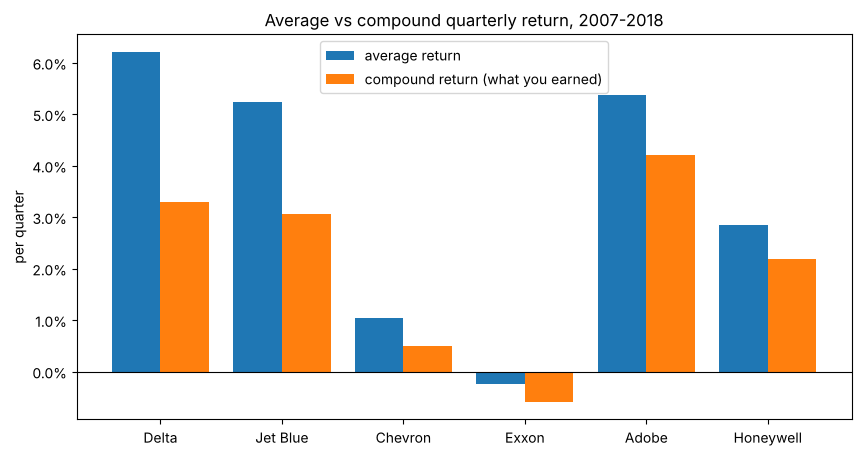

In [4]:
avg_return = quarterly_returns.mean()
growth = stock_data.iloc[-1] / stock_data.iloc[0]          # .iloc[-1] = last row, .iloc[0] = first row -> last price / first price
n_quarters = len(stock_data) - 1                           # 42 prices -> 41 quarters of growth
compound_return = growth ** (1 / n_quarters) - 1           # ** = power: the steady rate that gives the same growth

summary = pd.DataFrame({'avg quarterly return': avg_return,          # a DataFrame from a dictionary:
                        'compound quarterly return': compound_return, # each key = a column name,
                        '1 EUR became': growth})                     # each value = that column (rows matched by stock name)
print(summary.round(3))

plt.figure(figsize=(10, 5))
x = np.arange(len(summary))                                # NumPy version of range: [0, 1, ... 5] - you can do maths on it
plt.bar(x - 0.2, summary['avg quarterly return'], width=0.4, label='average return')                     # shifted 0.2 left
plt.bar(x + 0.2, summary['compound quarterly return'], width=0.4, label='compound return (what you earned)')  # shifted 0.2 right
plt.xticks(x, summary.index)                               # tick positions + labels in one call (summary.index = stock names)
plt.axhline(0, color='black', linewidth=0.8)               # horizontal line at 0
plt.gca().yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))   # gca() = "get current axes" (the ax object); y-axis as %
plt.ylabel('per quarter')
plt.title('Average vs compound quarterly return, 2007-2018')
plt.legend(loc='upper center')
plt.savefig(CHARTS + '01_01_avg_vs_compound_return.png')
plt.show()

**Delta has the highest *average* return, but Adobe grew the most** (1 EUR -> 5.40 EUR vs 3.78 EUR). The average rewards stocks that jump around a lot:

```text
+50%, then -50%:   average = 0%
100 EUR -> 150 EUR -> 75 EUR   -> you lost 25%
```

The bigger the swings, the bigger the gap between the average and the compound return - see Delta and Jet Blue (airlines, very volatile) vs Chevron (small gap). Mean-variance optimization uses the average; just remember it is not "what I actually earned".

- **Compound return** (geometric mean): `(last / first) ** (1 / periods) - 1`.
- Side-by-side bars without the `create_x` template: `x - 0.2` and `x + 0.2` with `width=0.4` - works because `np.arange` is a NumPy array (on a `range` you can't subtract).

### The six stocks
Codecademy calls them "six airline stocks", but only two are airlines:

| stock | sector |
|---|---|
| Delta, Jet Blue | airlines |
| Chevron, Exxon | oil |
| Adobe | software |
| Honeywell | industrial |

That matters for diversification later: one might expect airlines and oil to move *against* each other (fuel is an airline's biggest cost) - [section 4](#4.-Inputs:-Covariance-Matrix-I---risk-and-covariance) checks it in the data.

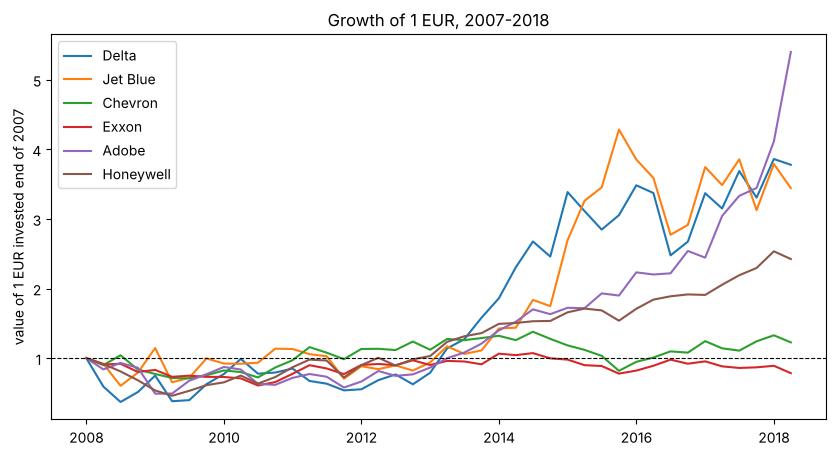

In [5]:
growth_of_1 = stock_data / stock_data.iloc[0]      # every price divided by its first price -> all stocks start at 1

plt.figure(figsize=(10, 5))
for stock in growth_of_1.columns:                                   # one line per stock
    plt.plot(growth_of_1.index, growth_of_1[stock], label=stock)    # x = dates (the index), y = that stock's column
plt.axhline(1, color='black', linewidth=0.8, linestyle='--')        # break-even line: above 1 = profit
plt.ylabel('value of 1 EUR invested end of 2007')
plt.title('Growth of 1 EUR, 2007-2018')
plt.legend()
plt.savefig(CHARTS + '01_01b_growth_of_1_eur.png')
plt.show()

- `stock_data / stock_data.iloc[0]` - divides every row by the first row: all six stocks start at 1, so they can share one chart.
- With `Date` as the index, `growth_of_1.index` gives real dates on the x-axis.
- Visible: 2008 crash, airlines' steep recovery, oil's fall in 2014-2015, Adobe's run from 2016.

## 2. Inputs: Expected Return II - weights
**Task:** 10,000 USD invested in three companies - 3,000 in Nike, 2,000 in Under Armour, 5,000 in Skechers. Calculate the weight of each.

**Weight** = money in this asset / total money in the portfolio. All weights add up to 1.

In [6]:
weight_nike = 3000/10000
weight_ua = 2000/10000
weight_skechers = 5000/10000

print(weight_nike, weight_ua, weight_skechers)

0.3 0.2 0.5


**Why weights?** They make a portfolio independent of its size - "30% in Nike" means the same with 10,000 USD or 10 million. And the weights are exactly what the optimizer chooses later: the efficient frontier is a search for the best weights.

### Shorter way: NumPy
One line instead of three, no repeated `10000` - change one amount and all weights update:

[0.3 0.2 0.5]
1.0


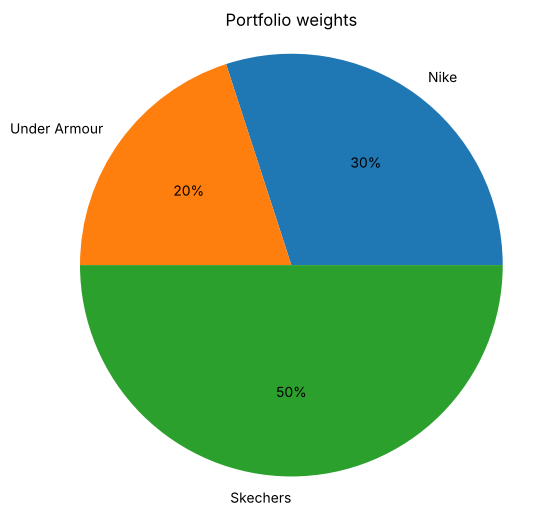

In [7]:
amounts = np.array([3000, 2000, 5000])      # Nike, Under Armour, Skechers - as a NumPy array, so we can divide all at once
weights = amounts / amounts.sum()           # every amount divided by the total -> [0.3, 0.2, 0.5]
print(weights)
print(weights.sum())                        # -> 1.0  quick check

plt.figure(figsize=(6, 6))
plt.pie(weights, labels=['Nike', 'Under Armour', 'Skechers'], autopct='%.0f%%')
plt.axis('equal')
plt.title('Portfolio weights')
plt.savefig(CHARTS + '01_02_portfolio_weights.png')
plt.show()

- R: `amounts / sum(amounts)`.
- A pie fits here - the parts add up to a real whole (the portfolio).
- **Finance:** weights can also be **negative** - short selling (borrow a stock and sell it, betting it falls). The weights still add up to 1.

## 3. Inputs: Expected Return III - portfolio return
**Task:** expected return of a portfolio with Nike (weight 0.8, return 1.4%), Under Armour (0.16, 0.8%) and Skechers (0.04, 7.0%).

The expected return of a portfolio is the **weighted sum** of its assets' expected returns - the y-axis of the efficient frontier:

```text
E(R) = w1*R1 + w2*R2 + w3*R3
     = 0.8 * 1.4%  +  0.16 * 0.8%  +  0.04 * 7.0%
     = 1.12%       +  0.128%       +  0.28%        = 1.53%
```

In [8]:
expected_return = 0.8*0.014+ 0.16*0.008+ 0.04*0.07

print('The expected return is equal to {:.2f}%'.format(expected_return))   # Codecademy's print
print('The expected return is equal to {:.2%}'.format(expected_return))    # correct

The expected return is equal to 0.02%
The expected return is equal to 1.53%


### Catch: Codecademy's print is wrong
`expected_return` is a decimal (0.01528), but `'{:.2f}%'` just puts a % sign behind it -> **"0.02%"**, 100x too small. Two fixes:
- `'{:.2%}'` - multiplies by 100 **and** adds the % sign -> **1.53%**
- or `'{:.2f}%'.format(expected_return * 100)`

Same idea as `autopct='%0.1f%%'` and `PercentFormatter(1.0)`: a decimal and a percentage are different numbers - check which one you have.

### Shorter way: `np.dot` / `@`
"Multiply pairwise, then add up" is a **dot product**:

1.53%
1.53%


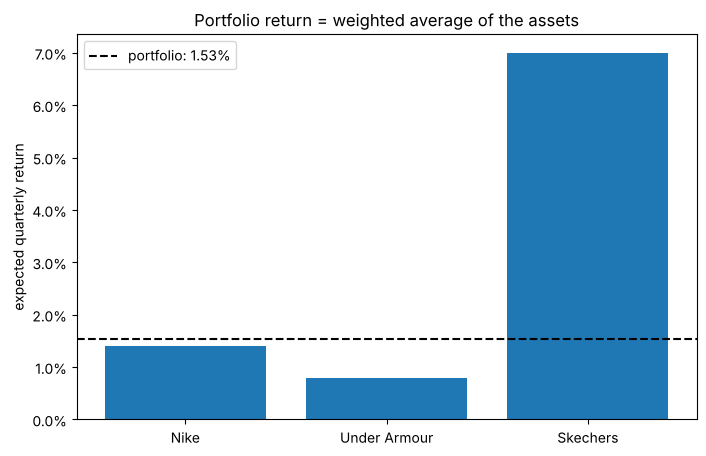

In [9]:
weights = np.array([0.8, 0.16, 0.04])           # Nike, Under Armour, Skechers
returns = np.array([0.014, 0.008, 0.07])

print(f'{np.dot(weights, returns):.2%}')         # dot product: multiply pairwise, add up -> 1.53%
print(f'{weights @ returns:.2%}')                # @ = same thing, shorter. f'{...:.2%}' = show as % with 2 decimals

names = ['Nike', 'Under Armour', 'Skechers']
plt.figure(figsize=(8, 5))
plt.bar(range(len(names)), returns)
plt.axhline(weights @ returns, color='black', linestyle='--', label='portfolio: 1.53%')   # dashed line at the portfolio return
plt.xticks(range(len(names)), names)                                                      # positions + labels in one call
plt.gca().yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))          # y-axis as %
plt.ylabel('expected quarterly return')
plt.title('Portfolio return = weighted average of the assets')
plt.legend()
plt.savefig(CHARTS + '01_03_portfolio_return.png')
plt.show()

```text
weights @ returns
[0.8, 0.16, 0.04]
   *    *     *         multiply pairwise
[0.014, 0.008, 0.07]
= 0.0112 + 0.00128 + 0.0028 = 0.01528
```

- R: `sum(weights * returns)` or `weights %*% returns`.
- f-strings: `f'{value:.2%}'` - same format codes as `.format()`, written inside the string.
- **The portfolio return always lies between the lowest and highest asset return** - it's a weighted average. Skechers has the best return, but with only 4% of the money it barely lifts the portfolio; Nike's 80% pulls it close to 1.4%.
- **Return averages like this - risk does not.** That's what the covariance matrix (next sections) is for.

## 4. Inputs: Covariance Matrix I - risk and covariance
*(Codecademy's exercise here is only a guess from a price chart - not kept. Concepts only.)*

**Why:** if returns were predictable, we'd put all our money into the asset with the highest expected return. They aren't - so besides the *mean* (expected return) we need a number for *risk*.

| term | measures | in words |
|---|---|---|
| **variance** | one asset | how much its returns jump around - its own risk. Big variance = unpredictable = risky |
| **covariance** | a pair of assets | do the two jump around **together**? |

**Three kinds of covariance:**

| covariance | value | meaning | example |
|---|---|---|---|
| positive | > 0 | when one goes up, the other usually goes up too | two airlines - same fuel prices, same travel demand |
| negative | < 0 | when one goes up, the other usually goes down | a company and its biggest cost (in theory: airlines vs oil) |
| none (uncorrelated) | = 0 | no pattern | companies in unrelated businesses |

**Why it matters for a portfolio:** a portfolio's risk depends on the variance of each asset **and** the covariance of every pair. Assets that don't move together partly cancel each other's swings - that's diversification, and the reason the covariance matrix is the second input of mean-variance optimization.

### Trap: covariance is about returns, not prices
A price chart shows long trends (one stock falls for years, another rises at the end) - that's not what covariance measures. It asks: **in the same period, did both move in the same direction?**

```text
quarter      0->1   1->2   2->3   3->4   ...
stock A       up    down   down    up
stock B      down   down    up    down
             ----   ----   ----   ----
             opp.   same   opp.   opp.     mostly opposite -> negative
```

### In our six stocks
Each dot is one quarter: x = return of one stock, y = return of the other. The number is the correlation (covariance scaled to -1 ... +1, calculated in the next section).

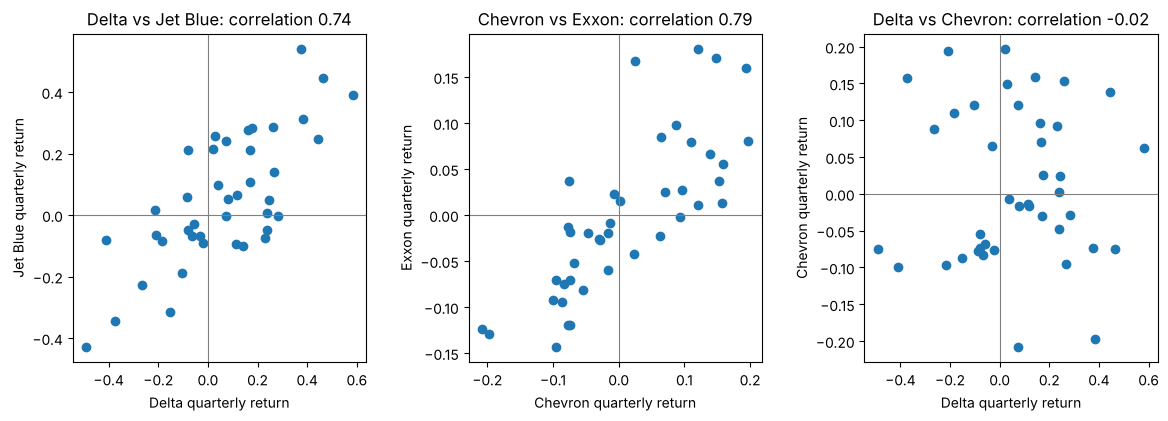

In [10]:
quarterly_returns = stock_data.pct_change()

pairs = [('Delta', 'Jet Blue'), ('Chevron', 'Exxon'), ('Delta', 'Chevron')]   # a list of pairs (tuples)

plt.figure(figsize=(14, 4.5))
for i, (a, b) in enumerate(pairs, start=1):    # i = 1, 2, 3 (counter); (a, b) = the two names of the current pair
    plt.subplot(1, 3, i)                       # box i of a 1 x 3 grid
    plt.scatter(quarterly_returns[a], quarterly_returns[b])   # one dot per quarter
    plt.axhline(0, color='gray', linewidth=0.8)               # horizontal line at 0
    plt.axvline(0, color='gray', linewidth=0.8)               # vertical line at 0 -> 4 areas: both up / both down / opposite
    corr = quarterly_returns[a].corr(quarterly_returns[b])    # correlation of the two columns (explained in section 5)
    plt.title(f'{a} vs {b}: correlation {corr:.2f}')          # f-string: {a}, {b}, {corr} are filled in
    plt.xlabel(f'{a} quarterly return')
    plt.ylabel(f'{b} quarterly return')

plt.subplots_adjust(wspace=0.35, bottom=0.15)
plt.savefig(CHARTS + '01_04_covariance_pairs.png')
plt.show()

| pair | pattern | why |
|---|---|---|
| Delta vs Jet Blue | dots along a rising line - **positive** | both airlines: same fuel prices, same travel demand |
| Chevron vs Exxon | **positive** | both oil: both follow the oil price |
| Delta vs Chevron | a cloud, no direction - **about 0** | airline vs oil |

**Surprise:** airlines vs oil is *not* negative here - it's close to 0. The theory ("fuel costs hurt airlines when oil rises") is real, but other forces (the 2008 crash hit everything; airlines hedge their fuel costs) wash it out. **Check in the data - don't assume.** For diversification, ~0 is still very useful: their swings don't line up, so they partly cancel.

- `enumerate(pairs, start=1)` - loops over the pairs **and** counts 1, 2, 3 - the subplot index.
- `for i, (a, b) in ...` - unpacks each pair into two names in one go.
- `plt.axhline(0)` / `plt.axvline(0)` - split the chart into "both up", "both down" and "opposite" quarters.

## 5. Inputs: Covariance Matrix II - the covariance matrix
**Task:** calculate the covariance matrix of the six stocks' quarterly returns and save it to `returns_cov`.

All variances and covariances in one table - the second input of mean-variance optimization:

```text
              asset 1      asset 2      asset 3
asset 1   [ var(1)       cov(1,2)     cov(1,3) ]    diagonal  = variance of each asset (its own risk)
asset 2   [ cov(1,2)     var(2)       cov(2,3) ]    off-diag. = covariance of each pair
asset 3   [ cov(1,3)     cov(2,3)     var(3)   ]    symmetric: cov(1,2) = cov(2,1)
```

In [11]:
stock_data_raw = pd.read_csv(path)
selected=list(stock_data_raw.columns[1:])

returns_quarterly = stock_data_raw[selected].pct_change()
expected_returns = returns_quarterly.mean()

returns_cov = returns_quarterly.cov()
print(returns_cov.round(4))

            Delta  Jet Blue  Chevron   Exxon   Adobe  Honeywell
Delta      0.0578    0.0379  -0.0004  0.0021  0.0042     0.0081
Jet Blue   0.0379    0.0450  -0.0018  0.0024 -0.0015     0.0055
Chevron   -0.0004   -0.0018   0.0110  0.0070  0.0046     0.0070
Exxon      0.0021    0.0024   0.0070  0.0072  0.0031     0.0062
Adobe      0.0042   -0.0015   0.0046  0.0031  0.0225     0.0113
Honeywell  0.0081    0.0055   0.0070  0.0062  0.0113     0.0132


- My code used `stock_data`; here it's `stock_data_raw`, because in this notebook `stock_data` already has `Date` as its index (section 1).
- `.cov()` on a DataFrame - every column against every column. R: `cov(returns, use = "complete.obs")`.
- **Delta's variance 0.0578 is 8x Exxon's 0.0072** - airlines are far riskier than oil majors.

### Two catches in the Codecademy text
**1. Their example calculates the covariance of prices, not returns.** The NYTimes / Twitter / Fox table they call `portfolio` holds prices (16.14, 62.36 ...), and they run `.cov()` on it directly. That contradicts the rule from [section 4](#4.-Inputs:-Covariance-Matrix-I---risk-and-covariance): covariance belongs on **returns** - prices mostly measure shared long-term trends. (In the exercise itself, `.cov()` is correctly run on returns.)

**2. "All of the assets are positively covarying" - not true here.** Three pairs are slightly negative: Delta-Chevron, Jet Blue-Chevron and Jet Blue-Adobe. They are tiny (close to 0) - the real point stands: few companies move against each other, most move with the market or not at all.

### Covariance is hard to read - correlation fixes it
Covariance depends on how volatile each stock is: 0.0379 (Delta-Jet Blue) and 0.0070 (Chevron-Exxon) look very different, but both pairs are strongly linked. **Correlation** scales covariance to -1 ... +1:

```text
correlation(a, b) = cov(a, b) / (std(a) * std(b))

 +1   move perfectly together
  0   no pattern
 -1   move perfectly opposite
```

           Delta  Jet Blue  Chevron  Exxon  Adobe  Honeywell
Delta       1.00      0.74    -0.02   0.10   0.12       0.29
Jet Blue    0.74      1.00    -0.08   0.13  -0.05       0.23
Chevron    -0.02     -0.08     1.00   0.79   0.29       0.58
Exxon       0.10      0.13     0.79   1.00   0.24       0.63
Adobe       0.12     -0.05     0.29   0.24   1.00       0.65
Honeywell   0.29      0.23     0.58   0.63   0.65       1.00
Delta        0.240
Jet Blue     0.212
Chevron      0.105
Exxon        0.085
Adobe        0.150
Honeywell    0.115
dtype: float64


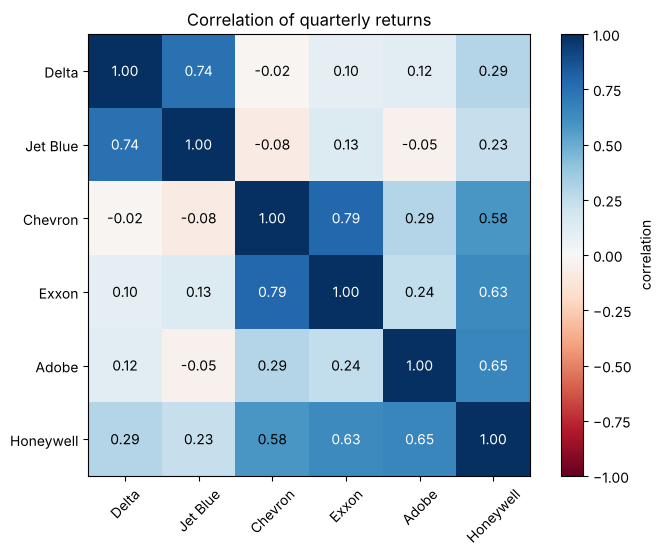

In [12]:
returns_corr = returns_quarterly.corr()           # correlation matrix: every stock against every stock, -1 ... +1
volatility = returns_quarterly.std()              # std = square root of the variance

print(returns_corr.round(2))
print(volatility.round(3))

plt.figure(figsize=(8, 6.5))
plt.imshow(returns_corr, cmap='RdBu', vmin=-1, vmax=1)    # draw the 6 x 6 table as coloured squares (heatmap)
                                                          # cmap='RdBu' = colour scale red -> white -> blue
                                                          # vmin/vmax = fix the scale at -1 ... +1, so 0 is white
plt.colorbar(label='correlation')                         # the colour legend on the right
plt.xticks(range(len(selected)), selected, rotation=45)   # stock names under the columns, tilted
plt.yticks(range(len(selected)), selected)                # stock names next to the rows
for i in range(len(selected)):                            # i = row number 0 ... 5
    for j in range(len(selected)):                        # j = column number 0 ... 5 (loop inside a loop: 36 squares)
        value = returns_corr.iloc[i, j]                   # the number in row i, column j
        plt.text(j, i, f'{value:.2f}', ha='center', va='center',   # write it in the square: x = column j, y = row i,
                 color='white' if abs(value) > 0.6 else 'black')   # centred; white text on dark squares (one-line if)
plt.title('Correlation of quarterly returns')
plt.subplots_adjust(bottom=0.2)                           # room at the bottom for the tilted names
plt.savefig(CHARTS + '01_05_correlation_heatmap.png')
plt.show()

- `plt.imshow(table)` - draws a table as coloured squares (a **heatmap**). `cmap='RdBu'` = red for negative, blue for positive; `vmin=-1, vmax=1` fixes the colour scale so 0 is white.
- `plt.text(j, i, ...)` - writes the number into each square: **column first (x), then row (y)**. `color='white' if ... else 'black'` - a one-line if: white text where the square is dark.
- `.std()` = square root of the variance = **volatility**, back in % units: Delta's returns swing about 24% per quarter, Exxon's about 8.5%.

**What the heatmap shows:** two blocks - airlines together (0.74), oil together (0.79), Honeywell linked to most (an industrial company follows the whole economy). Airlines vs oil/software: white - about 0. **That's where diversification comes from:** combining assets from different white areas.

**Coming next:** the portfolio's risk uses the whole matrix - `weights @ returns_cov @ weights`. Unlike the expected return, it's **not** a simple weighted average.

## 6. Efficient Frontier I - 5,000 random portfolios
**Task:** use Codecademy's `return_portfolios()` (from `rf.py`) to create 5,000 portfolios with random weights, save them to `random_portfolios`, print the first five.

Each portfolio gets the two numbers of the mean-variance chart: **expected return** (y) and **volatility** (x).

Codecademy's function, with my comments:

In [13]:
def return_portfolios(expected_returns, cov_matrix):
  np.random.seed(1)                       # fixed start for the random numbers -> same "random" portfolios every run
  port_returns = []
  port_volatility = []
  stock_weights = []

  selected = (expected_returns.axes)[0]   # the stock names (index of the expected_returns Series)

  num_assets = len(selected)              # 6
  num_portfolios = 5000

  for single_portfolio in range(num_portfolios):
    weights = np.random.random(num_assets)                                  # 6 random numbers between 0 and 1
    weights /= np.sum(weights)                                              # /= : divide by their sum -> weights add up to 1
    returns = np.dot(weights, expected_returns)                             # portfolio return = weights @ returns (section 3)
    volatility = np.sqrt(np.dot(weights.T, np.dot(cov_matrix, weights)))   # portfolio risk - see below
    port_returns.append(returns)
    port_volatility.append(volatility)
    stock_weights.append(weights)

    portfolio = {'Returns': port_returns,       # dictionary of columns (indented too far by Codecademy:
                 'Volatility': port_volatility} # rebuilt in every loop - works, just unnecessary)

  for counter,symbol in enumerate(selected):    # counter = 0..5, symbol = stock name
    portfolio[symbol +' Weight'] = [Weight[counter] for Weight in stock_weights]   # one weight column per stock

  df = pd.DataFrame(portfolio)

  column_order = ['Returns', 'Volatility'] + [stock+' Weight' for stock in selected]
  df = df[column_order]                       # put the columns in this order

  return df

### Portfolio risk: the whole covariance matrix
```text
volatility = sqrt( w @ cov @ w )

w @ cov @ w  =  sum over every pair (i, j) of  w_i * w_j * cov(i, j)
             =  each asset's own variance (diagonal, weighted)
             +  every covariance between pairs (off-diagonal, weighted)
```
Return was a simple weighted average - risk isn't: the covariances add or subtract risk. Low or negative covariances -> lower portfolio risk. `sqrt` turns variance back into volatility (std).

My code:

In [14]:
random_portfolios = return_portfolios(expected_returns, returns_cov)
print(random_portfolios.head().round(4))

   Returns  Volatility  Delta Weight  Jet Blue Weight  Chevron Weight  \
0   0.0437      0.1477        0.2484           0.4290          0.0001   
1   0.0290      0.0893        0.0724           0.1344          0.1543   
2   0.0347      0.1054        0.0742           0.3186          0.0099   
3   0.0198      0.0835        0.0451           0.0636          0.2572   
4   0.0463      0.1432        0.2978           0.3040          0.0289   

   Exxon Weight  Adobe Weight  Honeywell Weight  
0        0.1801        0.0874            0.0550  
1        0.2095        0.1630            0.2664  
2        0.2432        0.1514            0.2027  
3        0.3110        0.1007            0.2224  
4        0.0133        0.0577            0.2984  


- Codecademy calls the matrix `cov_quarterly`; here it's `returns_cov` from section 5 - same matrix.
- Each row = one portfolio: its return, volatility, and the 6 weights it used.

## 7. Efficient Frontier II - plotting the portfolios
**Task:** scatter plot of the 5,000 random portfolios - volatility on x, expected return on y.

My code:

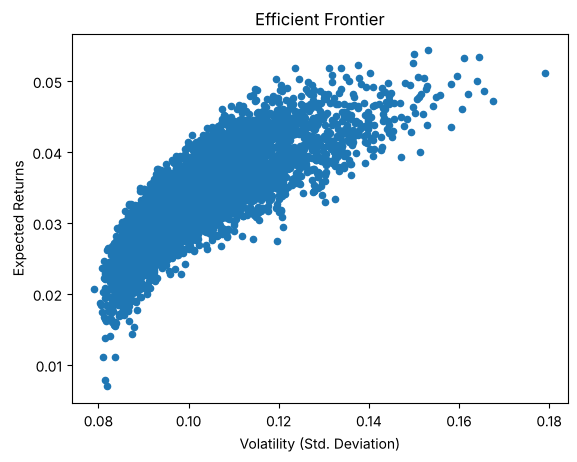

In [15]:
random_portfolios.plot.scatter(x='Volatility', y='Returns')
plt.xlabel('Volatility (Std. Deviation)')
plt.ylabel('Expected Returns')
plt.title('Efficient Frontier')
plt.savefig(CHARTS + '01_07_random_portfolios.png')
plt.show()

- `df.plot.scatter(x='col', y='col')` - pandas draws the scatter itself; just give the column names. Same as `plt.scatter(df['Volatility'], df['Returns'])`.
- The cloud has a **boomerang shape**. Best portfolios: **top-left edge** - highest return for each level of risk. That edge is the efficient frontier (next section); the title is a bit generous - the whole cloud isn't the frontier.
- The x-axis is **standard deviation** (volatility), not variance - same units as the returns.

### The single stocks on the same chart

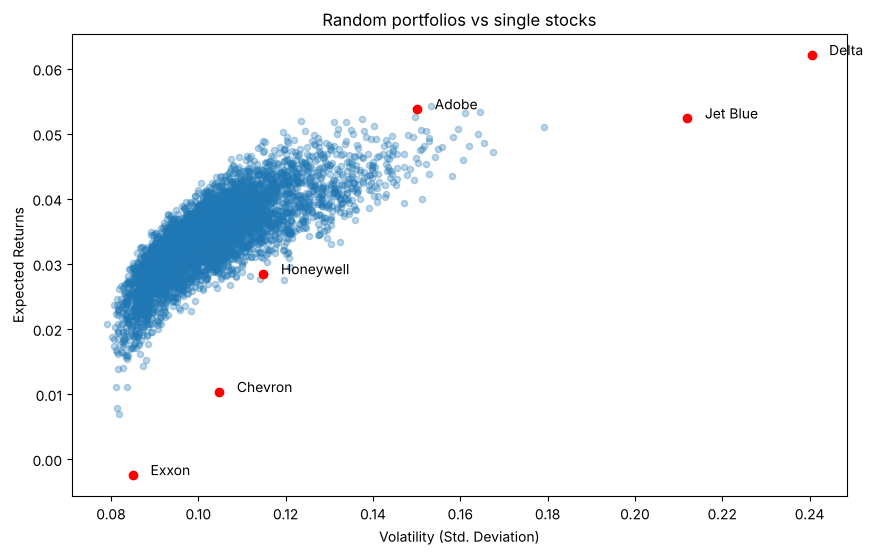

In [16]:
ax = random_portfolios.plot.scatter(x='Volatility', y='Returns', alpha=0.3, figsize=(10, 6))   # pandas returns the ax object
plt.scatter(volatility, expected_returns, color='red')            # the 6 single stocks (volatility from section 5)
for stock in expected_returns.index:                              # write each stock's name next to its dot
    plt.text(volatility[stock] + 0.004, expected_returns[stock], stock)   # + 0.004 = small shift right so the text doesn't cover the dot
plt.xlabel('Volatility (Std. Deviation)')
plt.ylabel('Expected Returns')
plt.title('Random portfolios vs single stocks')
plt.savefig(CHARTS + '01_07b_portfolios_vs_single_stocks.png')
plt.show()

- Delta and Jet Blue sit far right (very risky); portfolios reach almost the same return with about half the volatility.
- The safest portfolios (left edge, ~0.08) are **less risky than Exxon**, the least risky single stock - and earn ~2% per quarter instead of Exxon's -0.2%.

**Diversification on one chart:** mixing assets gives more return per unit of risk than almost any single stock.

## 8. Efficient Frontier III - finding the frontier
**Task:** use Codecademy's `optimal_portfolio()` to calculate the efficient frontier (`weights`, `returns`, `risks`) and draw it as a yellow line on the random portfolios.

The function uses `cvxopt`, an optimization library - install once locally: `py -m pip install cvxopt`.

Codecademy's function, with my comments:

In [17]:
import cvxopt as opt
from cvxopt import blas, solvers
solvers.options['show_progress'] = False      # don't print the solver's working for every one of the 100 portfolios

def optimal_portfolio(returns):
    n = returns.shape[1]                          # number of stocks (columns) -> 6
    returns = np.transpose(returns.to_numpy())    # table -> NumPy array, flipped: one row per stock
                                                  # (Codecademy: .as_matrix() - removed in newer pandas, .to_numpy() is the same)

    N = 100
    mus = [10**(5.0 * t/N - 1.0) for t in range(N)]   # 100 "risk aversion" levels from 0.1 to ~9,000 (10 to the power ...)

    # Convert to cvxopt matrices
    S = opt.matrix(np.cov(returns))               # covariance matrix (the risk input)
    pbar = opt.matrix(np.mean(returns, axis=1))   # expected return of each stock (axis=1: mean along each row)

    # Create constraint matrices
    G = -opt.matrix(np.eye(n))   # negative n x n identity matrix   } together: -w <= 0, i.e. every weight >= 0
    h = opt.matrix(0.0, (n ,1))  # a column of n zeros               }   -> no short selling
    A = opt.matrix(1.0, (1, n))  # a row of n ones                   } together: 1*w1 + ... + 1*wn = 1
    b = opt.matrix(1.0)          # the number 1                       }   -> weights add up to 1

    # Calculate efficient frontier weights using quadratic programming
    portfolios = [solvers.qp(mu*S, -pbar, G, h, A, b)['x']   # for each mu: find the weights that minimise
                  for mu in mus]                             #   mu * risk - return   (see below)
    ## CALCULATE RISKS AND RETURNS FOR FRONTIER
    returns = [blas.dot(pbar, x) for x in portfolios]            # return of each frontier portfolio (weights @ returns)
    risks = [np.sqrt(blas.dot(x, S*x)) for x in portfolios]      # volatility of each: sqrt(w @ cov @ w), as in section 6
    ## CALCULATE THE 2ND DEGREE POLYNOMIAL OF THE FRONTIER CURVE
    m1 = np.polyfit(returns, risks, 2)            # fit a curve (parabola) through the frontier points
    x1 = np.sqrt(m1[2] / m1[0])                   # a rule of thumb to pick one point on that curve
    # CALCULATE THE OPTIMAL PORTFOLIO
    wt = solvers.qp(opt.matrix(x1 * S), -pbar, G, h, A, b)['x']  # the weights of that one portfolio
    return np.asarray(wt), returns, risks

### What the optimizer does
For each of the 100 `mu` values it solves:

```text
find weights w that minimise   mu * (w @ cov @ w)  -  (w @ returns)
                                     \_________/       \_________/
                                        risk             return
subject to:   every weight >= 0   and   weights add up to 1

small mu  -> risk barely counts  -> high return, high risk    (top-right end of the frontier)
large mu  -> risk counts a lot   -> low risk, low return      (bottom-left end)
```

100 answers = 100 points along the top-left edge = the efficient frontier. "Quadratic programming" = optimizing something with a squared term (the risk) under constraints.

**Note:** `weights` is **one** portfolio, not the weights of all 100 - the function picks it with a fitted curve (a rule of thumb, not a standard method).

My code (moved above the plot - see the mistake below):

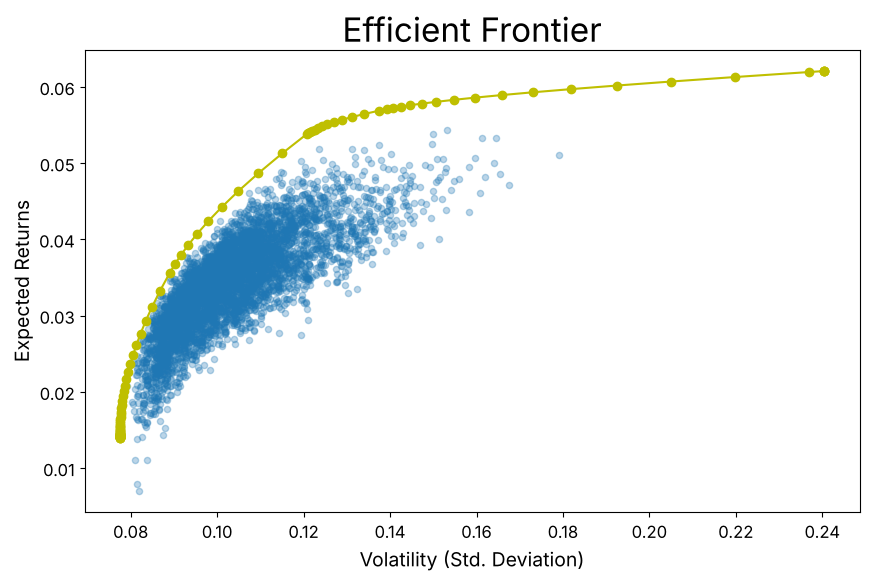

Delta        1.0
Jet Blue     0.0
Chevron      0.0
Exxon        0.0
Adobe        0.0
Honeywell    0.0
dtype: float64


In [18]:
weights, frontier_returns, frontier_risks = optimal_portfolio(returns_quarterly[1:])   # [1:] drops the NaN first row

random_portfolios.plot.scatter(x='Volatility', y='Returns', fontsize=12, alpha=0.3, figsize=(10, 6))
plt.plot(frontier_risks, frontier_returns, 'y-o')      # 'y-o' = yellow, solid line, round markers
plt.ylabel('Expected Returns',fontsize=14)
plt.xlabel('Volatility (Std. Deviation)',fontsize=14)
plt.title('Efficient Frontier', fontsize=24)
plt.savefig(CHARTS + '01_08_efficient_frontier.png')
plt.show()

print(pd.Series(weights.flatten(), index=selected).round(3))   # .flatten(): 6x1 table -> flat list; shown with stock names

### My mistake: calculated after the plot
I put the `optimal_portfolio(...)` line at the very end. At plot time `risks` and `returns` didn't exist yet - an error, but Codecademy's `try/except: pass` swallowed it, so **the yellow line silently didn't appear**.
- Calculate first, plot second.
- `try/except: pass` hides errors - fine for Codecademy's checker, dangerous in your own code.

**Renamed:** `returns`, `risks` -> `frontier_returns`, `frontier_risks` - `returns` would overwrite earlier variables (section 3).

**The chart:** the yellow line runs along the top-left edge - for every level of risk, nothing earns more; for every return, nothing is safer. It sits **above** the cloud: random weights almost never set several stocks to exactly 0, but the best portfolios often do.

**The "optimal" weights: 100% Delta.** The rule of thumb picked the top-right end of the frontier - all-in on the riskiest stock. Every point on the line is efficient; **which one is "best" depends on how much risk you accept** - the function's pick isn't meaningful on its own.

## 9. Diverse Portfolios Decrease Variance I - adding Nvidia
**Task:** add a seventh stock, Nvidia (high return, high risk), and compare the new efficient frontier (green) with the old one (yellow).

Data: [`data/stock_data_nvidia.csv`](../../data/stock_data_nvidia.csv) - the same six stocks plus Nvidia.

**Prediction:** the frontier gets **longer upward** (Nvidia's 7.5% beats Delta's 6.2%, with less risk) and **never gets worse** - the optimizer can always give Nvidia a weight of 0.

My code (Codecademy's script; the old frontier was loaded from a file Codecademy provided - here it's recalculated from section 8):

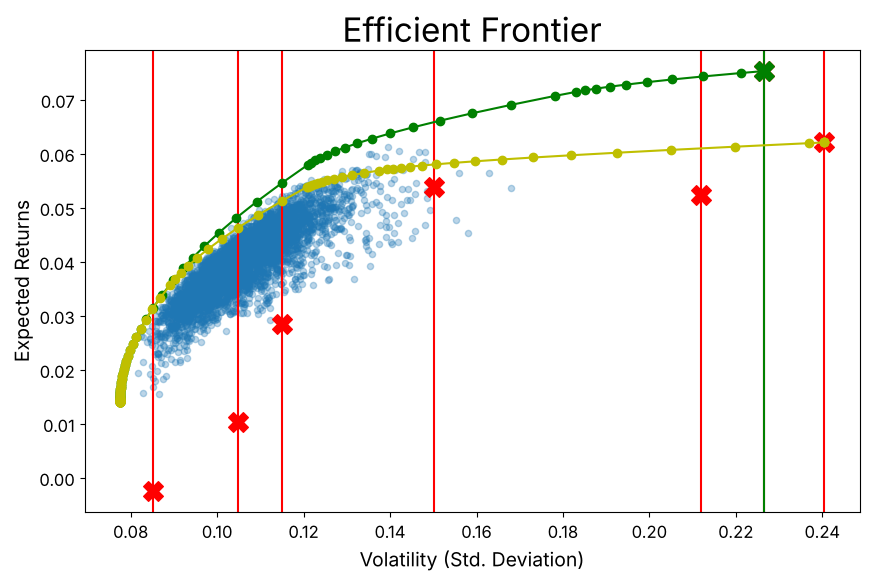

In [19]:
path_nvidia = '../../data/stock_data_nvidia.csv'

stock_data_nv = pd.read_csv(path_nvidia)
selected_nv = list(stock_data_nv.columns[1:])

returns_quarterly_nv = stock_data_nv[selected_nv].pct_change()
expected_returns_nv = returns_quarterly_nv.mean()
cov_quarterly_nv = returns_quarterly_nv.cov()

single_asset_std = np.sqrt(np.diagonal(cov_quarterly_nv))   # np.diagonal: the variances on the diagonal; sqrt -> std of each stock
df = return_portfolios(expected_returns_nv, cov_quarterly_nv)
weights_nv, returns_nv, risks_nv = optimal_portfolio(returns_quarterly_nv[1:])

df.plot.scatter(x='Volatility', y='Returns', fontsize=12, alpha=0.3, figsize=(10, 6))
plt.scatter(single_asset_std, expected_returns_nv, marker='X', color='red', s=200)   # marker='X' = cross, s = marker size
for xc in single_asset_std:                  # one vertical line per stock at its std
    plt.axvline(x=xc, color='red')

plt.axvline(single_asset_std[-1], color='green')                                         # [-1] = last item = Nvidia
plt.scatter(single_asset_std[-1], expected_returns_nv.iloc[-1], marker='X', color='green', s=200)
plt.plot(risks_nv, returns_nv, 'g-o')                    # new frontier, with Nvidia (green)
plt.plot(frontier_risks, frontier_returns, 'y-o')        # old frontier, 6 stocks (yellow, section 8)

plt.ylabel('Expected Returns',fontsize=14)
plt.xlabel('Volatility (Std. Deviation)',fontsize=14)
plt.title('Efficient Frontier', fontsize=24)
plt.savefig(CHARTS + '01_09_frontier_with_nvidia.png')
plt.show()

- Codecademy writes `expected_returns[-1]`; on a pandas Series with stock names as the index, `[-1]` is ambiguous - `.iloc[-1]` means "last by position".
- Renamed with `_nv` so the 6-stock variables from earlier sections stay intact.

**Result:**
- The green frontier reaches higher - up to Nvidia's 7.5% at less risk than Delta.
- At the left end both frontiers almost overlap; with Nvidia slightly better, never worse.
- **Some portfolios are less risky than the least risky single stock** (left of every red line) - combining assets that don't move together cancels part of their swings.

**Codecademy's claim**, more precisely: adding an asset never makes the efficient frontier worse; assets that don't move with the rest improve it most. Nvidia's correlation with Jet Blue is -0.04, with Delta 0.13 - that's why it helps.

**Catch:** Codecademy's table lists Exxon's std as 0.05 - from the same data it's **0.085** (section 5).

### Why more uncorrelated assets mean less (or equal) risk
**1. "Not affect": a new asset can't make the best portfolio worse.** The optimizer can give it a weight of 0 - the old portfolio is still available. The new frontier = all old options + new ones. (This is about the *best possible* mix - putting 50% into Nvidia would raise risk.)

**2. "Decrease": uncorrelated assets cancel each other's swings.** A bad quarter in one is often a normal one in the other. Equal weights, n uncorrelated assets, each 20% volatility:

```text
portfolio volatility = 20% / sqrt(n)

 n = 1  -> 20%    n = 2  -> 14.1%    n = 4  -> 10%    n = 10 -> 6.3%    n = 100 -> 2%
```

**3. The catch: real stocks are partly correlated.** With average correlation rho, risk levels off at a floor:

```text
portfolio variance = sigma^2 * ( rho  +  (1 - rho) / n )
                                 \_/     \___________/
                                 floor   shrinks as n grows

sigma = 20%, rho = 0.3:   n = 1 -> 20%   n = 10 -> 12.2%   n = 100 -> 11.1%   floor ~ 11%
```

- **Stock-specific risk** (one company's bad news) - diversified away.
- **Market risk** (a recession hits everyone) - stays: the floor. In our data the safest portfolios stop at ~0.077, not 0.

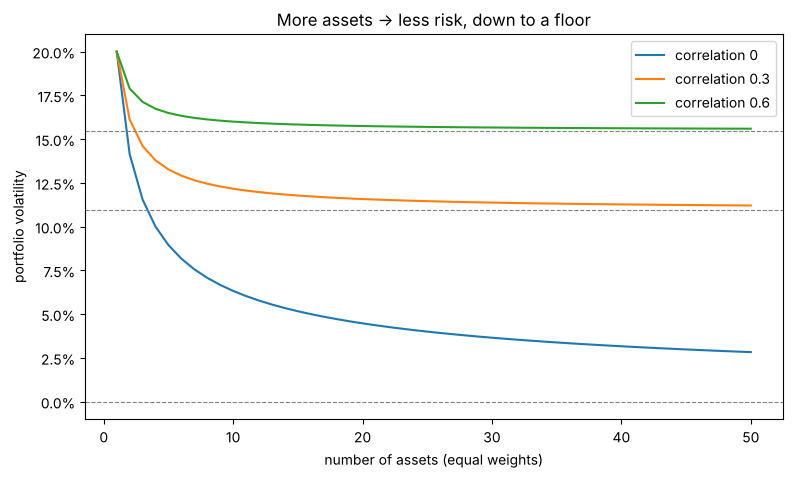

In [20]:
sigma = 0.20                     # volatility of each single asset
n = np.arange(1, 51)             # 1, 2, ... 50 assets

plt.figure(figsize=(9, 5))
for rho in [0, 0.3, 0.6]:                                        # three average correlations
    portfolio_vol = np.sqrt(sigma**2 * (rho + (1 - rho) / n))   # the formula above, for every n at once (NumPy array)
    plt.plot(n, portfolio_vol, label=f'correlation {rho}')
    plt.axhline(sigma * np.sqrt(rho), linestyle='--', color='gray', linewidth=0.8)   # the floor: sigma * sqrt(rho)

plt.gca().yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))   # y-axis as %
plt.xlabel('number of assets (equal weights)')
plt.ylabel('portfolio volatility')
plt.title('More assets -> less risk, down to a floor')
plt.legend()
plt.savefig(CHARTS + '01_09b_risk_vs_number_of_assets.png')
plt.show()

- Correlation 0: risk keeps falling towards 0. Correlation 0.3 / 0.6: it flattens at the dashed floor.
- Most of the benefit comes from the first ~10 assets.
- **Caveat:** correlations rise in a crisis (2008: nearly everything fell together) - diversification helps least when it's needed most.

## 10. Diverse Portfolios Decrease Variance II - adding Dexcom
**Task:** add an eighth stock, Dexcom (high risk, high return, but uncorrelated with most of the portfolio), and compare the three frontiers: 6 stocks (yellow), + Nvidia (green), + Dexcom (black).

Data: [`data/stocks_nvidia_dexcom.csv`](../../data/stocks_nvidia_dexcom.csv). Dexcom makes glucose monitors - a medical-device business that doesn't care about oil prices, air travel or software cycles.

**Key point:** for **return**, an asset's own number tells you everything. For **risk**, its own volatility tells you almost nothing - what matters is its **correlation** with what you already hold.

My code (Codecademy's script; the yellow and green frontiers come from sections 8 and 9 instead of Codecademy's files):

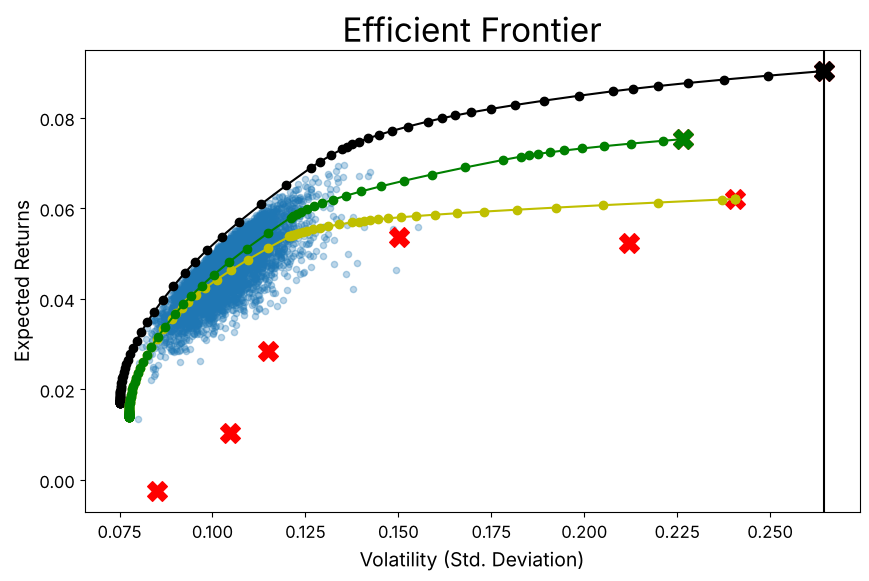

In [21]:
path_dexcom = '../../data/stocks_nvidia_dexcom.csv'

stock_data_dx = pd.read_csv(path_dexcom)
selected_dx = list(stock_data_dx.columns[1:])

returns_quarterly_dx = stock_data_dx[selected_dx].pct_change()
expected_returns_dx = returns_quarterly_dx.mean()
cov_quarterly_dx = returns_quarterly_dx.cov()

single_asset_std_dx = np.sqrt(np.diagonal(cov_quarterly_dx))
df = return_portfolios(expected_returns_dx, cov_quarterly_dx)
weights_dx, returns_dx, risks_dx = optimal_portfolio(returns_quarterly_dx[1:])

df.plot.scatter(x='Volatility', y='Returns', fontsize=12, alpha=0.3, figsize=(10, 6))
plt.scatter(single_asset_std_dx, expected_returns_dx, marker='X', color='red', s=200)

plt.axvline(single_asset_std_dx[-1], color='black')
plt.scatter(single_asset_std_dx[-1], expected_returns_dx.iloc[-1], marker='X', color='black', s=200)   # Dexcom (last)
plt.scatter(single_asset_std_dx[-2], expected_returns_dx.iloc[-2], marker='X', color='green', s=200)   # Nvidia (second to last)
plt.plot(risks_dx, returns_dx, 'k-o')                     # 'k' = black: + Dexcom
plt.plot(frontier_risks, frontier_returns, 'y-o')         # 6 stocks (section 8)
plt.plot(risks_nv, returns_nv, 'g-o')                     # + Nvidia (section 9)

plt.ylabel('Expected Returns',fontsize=14)
plt.xlabel('Volatility (Std. Deviation)',fontsize=14)
plt.title('Efficient Frontier', fontsize=24)
plt.savefig(CHARTS + '01_10_frontier_with_dexcom.png')
plt.show()

- `[-2]` / `.iloc[-2]` = second to last = Nvidia.
- The black frontier sits **above and left** of the others: more return at every risk, less risk at every return.

### Proof: Dexcom's correlations
Nvidia and Dexcom are both risky, high-return stocks - the difference is how they move with the rest:

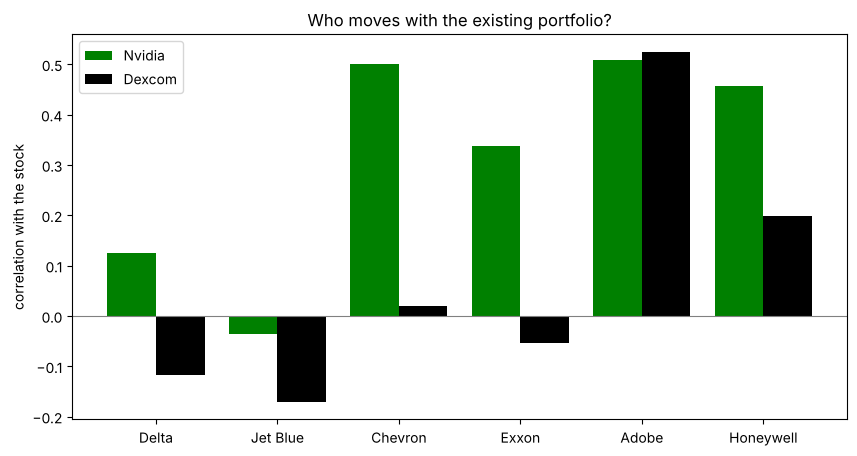

        avg return  volatility
Nvidia       0.075       0.227
Dexcom       0.090       0.265


In [22]:
corr_dx = returns_quarterly_dx.corr()          # correlation matrix of all 8 stocks
six = selected_dx[:6]                           # the original six stocks ([:6] = first six)

x = np.arange(len(six))
plt.figure(figsize=(10, 5))
plt.bar(x - 0.2, corr_dx.loc[six, 'Nvidia'], width=0.4, label='Nvidia', color='green')   # .loc[rows, column]: Nvidia's correlation with each of the six
plt.bar(x + 0.2, corr_dx.loc[six, 'Dexcom'], width=0.4, label='Dexcom', color='black')
plt.axhline(0, color='gray', linewidth=0.8)
plt.xticks(x, six)
plt.ylabel('correlation with the stock')
plt.title('Who moves with the existing portfolio?')
plt.legend()
plt.savefig(CHARTS + '01_10b_nvidia_vs_dexcom_correlation.png')
plt.show()

print(pd.DataFrame({'avg return': expected_returns_dx, 'volatility': single_asset_std_dx}).loc[['Nvidia', 'Dexcom']].round(3))

| | return | volatility | correlation with the six |
|---|---|---|---|
| Nvidia | 7.5% | 0.23 | positive with oil, Adobe, Honeywell (0.3-0.5) |
| Dexcom | 9.0% | 0.27 | **negative or ~0** with airlines and oil; only Adobe 0.52 |

- Dexcom is even **riskier** than Nvidia on its own - and still lowers portfolio risk, because its swings come at different times.
- Honest caveat: Dexcom also has the highest return of all eight, so part of the lift comes from that. The leftward shift (less risk) is the correlation effect.

**Rule:** to raise return - add a higher-return asset. To lower risk - add an asset that doesn't move with what you hold, however risky it looks alone.